# Used Car Price Prediction using Machine Learning

## Problem Statement

The objective of this project is to predict the selling price of a used car
based on various features such as year, present price, kilometers driven,
fuel type, seller type, transmission, and number of previous owners.

This is a supervised machine learning regression problem because the target
variable, Selling_Price, is a continuous numerical value.

## 1. Importing Required Libraries

In this section, we import the Python libraries required for data loading,
data analysis, visualization, preprocessing, model building, and evaluation.

In [21]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## 2. Loading the Dataset

The dataset is loaded using pandas. After loading the data, we will inspect
the first few records to understand the structure of the dataset.

In [22]:
import pandas as pd

In [23]:
df = pd.read_csv("car data.csv")

In [24]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon_r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Understanding the Dataset

We examine the number of rows and columns, data types, and basic statistical
information to understand the dataset before preprocessing.

In [25]:
print("Shape of dataset:", df.shape)

Shape of dataset: (20, 9)


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       20 non-null     str    
 1   Year           20 non-null     int64  
 2   Selling_Price  20 non-null     float64
 3   Present_Price  20 non-null     float64
 4   Kms_Driven     20 non-null     int64  
 5   Fuel_Type      20 non-null     str    
 6   Seller_Type    20 non-null     str    
 7   Transmission   20 non-null     str    
 8   Owner          20 non-null     int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 1.5 KB


In [27]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,20.000000,20.000000,20.000000,20.000000,20.0
mean,2014.550000,5.785000,8.232500,30883.400000,0.0
std,2.282081,2.242948,2.216106,19158.950233,0.0
min,2009.000000,2.250000,3.600000,2071.000000,0.0
25%,2014.000000,3.325000,7.125000,17847.000000,0.0
50%,2015.000000,6.625000,8.750000,34464.500000,0.0
75%,2016.000000,7.462500,9.872500,42587.500000,0.0
max,2018.000000,9.250000,10.790000,77427.000000,0.0


In [28]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='str')

## 4. Checking Missing Values

Missing values can affect machine learning models. Therefore, we check every
column for missing values before training the models.

In [29]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

## 5. Checking Duplicate Records

Duplicate records can cause certain observations to receive more importance
during model training. Therefore, duplicate rows are identified and removed
if they exist.

In [30]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1


In [31]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (19, 9)


## 6. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution of
variables and relationships between the features and the target variable.

In [32]:
import matplotlib.pyplot as plt

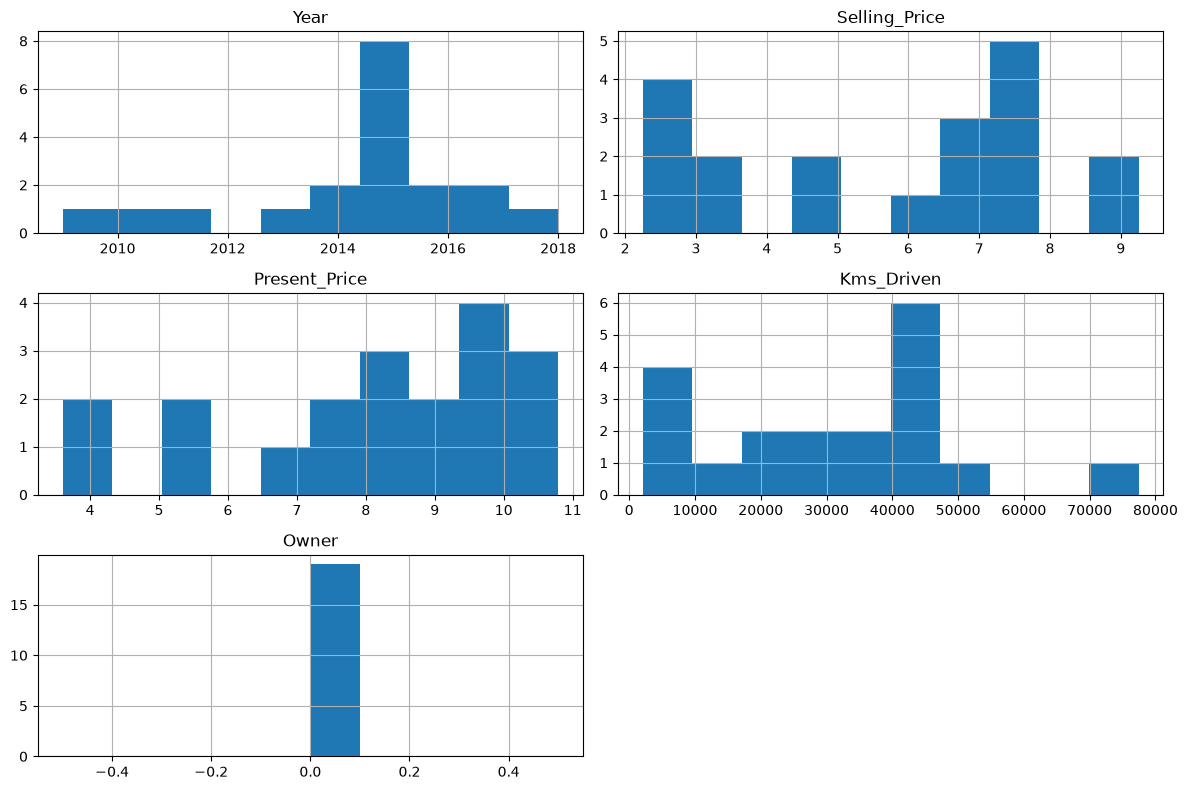

In [33]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

selling price distribution

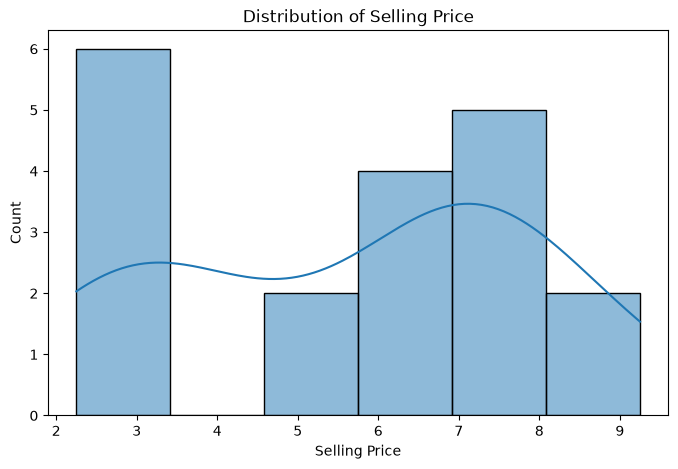

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], kde=True)

plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")

plt.show()

correlation analysis

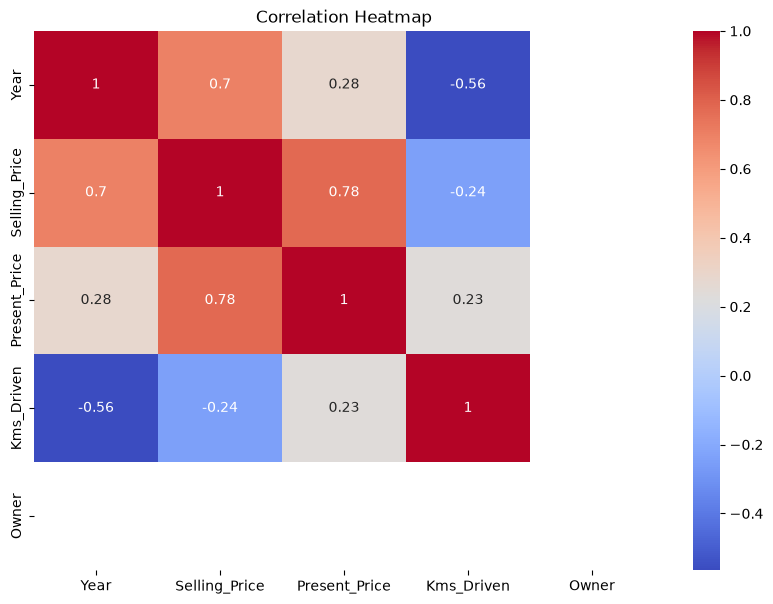

In [35]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Fuel_Type
Seller_Type
Transmission

In [36]:
print(df["Fuel_Type"].value_counts())
print(df["Seller_Type"].value_counts())
print(df["Transmission"].value_counts())

Fuel_Type
Diesel    10
Petrol     8
CNG        1
Name: count, dtype: int64
Seller_Type
Dealer        18
Individual     1
Name: count, dtype: int64
Transmission
Manual       18
Automatic     1
Name: count, dtype: int64


## 7. Feature Engineering

The Year column represents the manufacturing year. A more meaningful feature
for used-car pricing is the age of the vehicle. Therefore, Car_Age is created
from the manufacturing year.

In [37]:
current_year = 2026

df["Car_Age"] = current_year - df["Year"]

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon_r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


## 8. Feature Selection

Selling_Price is selected as the target variable because the objective of this
project is to predict the selling price of a used car.

Car_Name is not used as a direct numerical feature because it contains many
different car names and is not directly suitable for simple numerical modeling.

In [38]:
X = df.drop(columns=["Selling_Price", "Car_Name", "Year"])
y = df["Selling_Price"]

In [39]:
print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type',
       'Transmission', 'Owner', 'Car_Age'],
      dtype='str')

Target:
Selling_Price


## 9. Train-Test Split

The dataset is divided into training and testing sets. The training data is
used to learn patterns, while the testing data is used to evaluate how well
the model performs on unseen data.

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [42]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (15, 7)
Testing data: (4, 7)


Identify numerical and categorical columns

In [43]:
import numpy as np

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'string']
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']
Categorical features: ['Fuel_Type', 'Seller_Type', 'Transmission']


## 10. Data Preprocessing

Numerical features are handled using median imputation and scaling.
Categorical features are handled using the most frequent value for missing
data and One-Hot Encoding to convert categories into numerical values.

A ColumnTransformer is used so that different preprocessing operations can
be applied to numerical and categorical columns.

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [45]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [46]:
from sklearn.compose import ColumnTransformer

In [47]:

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## 11. Model 1 – Linear Regression

Linear Regression is used as a baseline regression model. It attempts to
model the relationship between the input features and selling price using
a linear relationship.

In [48]:
from sklearn.linear_model import LinearRegression

In [49]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [51]:
linear_mae = mean_absolute_error(y_test, linear_pred)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_pred)
)

linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression Results")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R² Score:", linear_r2)

Linear Regression Results
MAE: 0.7798599040745102
RMSE: 1.012269674139394
R² Score: 0.7936173427628852


## 12. Model 2 – Decision Tree Regressor

Decision Tree Regression can capture non-linear relationships between car
features and selling price. It recursively divides the data into groups
based on feature values.

In [52]:
from sklearn.tree import DecisionTreeRegressor

In [53]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=5
        ))
    ]
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

In [54]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Results")
print("MAE:", tree_mae)
print("RMSE:", tree_rmse)
print("R² Score:", tree_r2)

Decision Tree Results
MAE: 1.5833333333333335
RMSE: 1.857268005551284
R² Score: 0.30524784603334454


## 13. Model 3 – Random Forest Regressor

Random Forest combines multiple decision trees and averages their predictions.
It is generally more robust than a single decision tree and can model complex
non-linear relationships.

In [55]:
from sklearn.ensemble import RandomForestRegressor

In [56]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)

In [57]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Results
MAE: 1.3211875000000042
RMSE: 1.5415157769627303
R² Score: 0.5213955910120825


## 14. Model 4 – Gradient Boosting Regressor

Gradient Boosting builds models sequentially, with each new model attempting
to improve the errors made by previous models. It is suitable for many
tabular regression problems.

In [58]:
from sklearn.ensemble import GradientBoostingRegressor

In [59]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ]
)

gradient_model.fit(X_train, y_train)

gradient_pred = gradient_model.predict(X_test)

In [60]:
gradient_mae = mean_absolute_error(y_test, gradient_pred)
gradient_rmse = np.sqrt(mean_squared_error(y_test, gradient_pred))
gradient_r2 = r2_score(y_test, gradient_pred)

print("Gradient Boosting Results")
print("MAE:", gradient_mae)
print("RMSE:", gradient_rmse)
print("R² Score:", gradient_r2)

Gradient Boosting Results
MAE: 1.3011219077677296
RMSE: 1.6473165867375343
R² Score: 0.4534437186423764


## 15. Model Comparison

Multiple regression algorithms are compared using MAE, RMSE, and R2 Score.

MAE and RMSE should be lower, while R2 Score should be higher.

In [61]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae,
        gradient_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse,
        gradient_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2,
        rf_r2,
        gradient_r2
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.779860,1.012270,0.793617
1,Decision Tree,1.583333,1.857268,0.305248
2,Random Forest,1.321188,1.541516,0.521396
3,Gradient Boosting,1.301122,1.647317,0.453444


Visualize model comparison

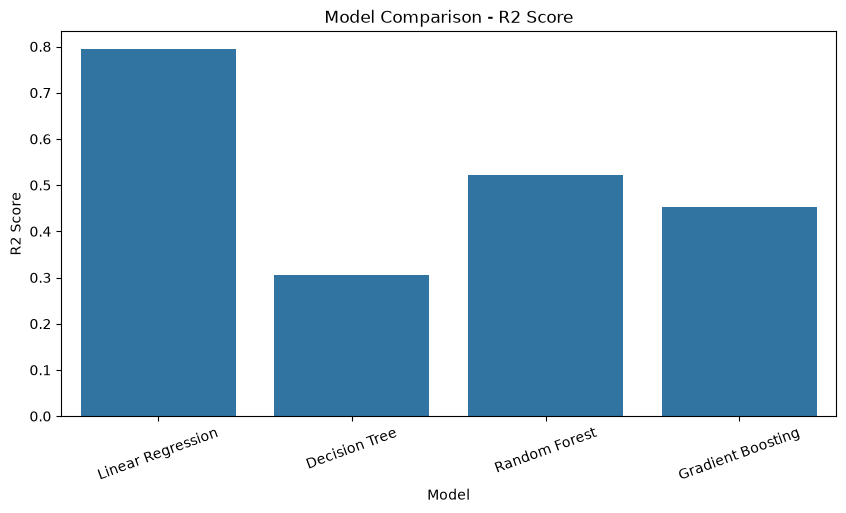

In [62]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison - R2 Score")
plt.xticks(rotation=20)
plt.show()

Select the best model automatically

In [63]:
best_model_name = results.loc[
    results["R2 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: Linear Regression


Hyperparameter tuning

Because your assignment says:

"advanced algorithms, validation and hyperparameter tuning only when required"

We can tune Random Forest.

In [64]:
from sklearn.model_selection import GridSearchCV

In [65]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]
)

In [66]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

In [67]:
grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, 

Find the best parameters:

In [68]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [69]:
tuned_pred = grid_search.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Random Forest
MAE: 1.3211875000000042
RMSE: 1.5415157769627303
R2 Score: 0.5213955910120825


Final model

## 16. Final Model Selection

After comparing the baseline models and evaluating the tuned Random Forest,
the model with the best validation/test performance is selected as the final
model.

The final model will be used for prediction on unseen car information.

In [70]:
final_model = grid_search

Make a new car prediction

This is required by your assignment.

Create a new DataFrame.

In [71]:
new_car = pd.DataFrame({
    "Present_Price": [5.5],
    "Kms_Driven": [40000],
    "Fuel_Type": ["Petrol"],
    "Seller_Type": ["Dealer"],
    "Transmission": ["Manual"],
    "Owner": [0],
    "Car_Age": [5]
})

In [72]:
new_car_encoded = pd.get_dummies(new_car, drop_first=True)

new_car_encoded = new_car_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

new_car_encoded

,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,5.5,40000,0,0,0,0,5


In [73]:
predicted_price = grid_search.predict(new_car_encoded)

print("Predicted Selling Price:", predicted_price[0])

Predicted Selling Price: 3.6232500000000054


In [74]:
price_in_rupees = predicted_price[0] * 100000

print("Predicted Car Price: ₹", round(price_in_rupees, 2))

Predicted Car Price: ₹ 362325.0


Final conclusion

Create a Markdown cell:

# 17. Final Conclusion

In this project, a machine learning regression system was developed to
predict the selling price of used cars.

The dataset was explored and preprocessed by checking missing values,
duplicates, data types, numerical and categorical features, and outliers.
Feature engineering was performed by creating the Car_Age feature.

Multiple regression algorithms including Linear Regression, Decision Tree,
Random Forest, and Gradient Boosting were trained and evaluated.

The models were compared using MAE, RMSE, and R2 Score. The best-performing
model was selected based on its predictive performance.

Finally, the selected model was used to predict the selling price of a new
unseen car.

This project demonstrates the complete machine learning workflow from data
understanding and preprocessing to model development, evaluation, selection,
and prediction.